# Thực nghiệm E1 tới E4: đọc chỉ số đồng hồ nước

Phúc, hoàn thiện issue #16. E1/E2 và phương pháp: PR #23; E3/E4: Quang, PR #24. Notebook đọc bảng gốc đã commit, không chọn lại tham số hoặc chạy lại tập đánh giá. Mọi số liệu và hình bên dưới được tính từ CSV, không chép tay.

Cấu hình được chọn trên dev_val trước khi đánh giá eval. Tập dựng mẫu 9.577 ảnh (chỉ dùng 6.178 ảnh không half-word để dựng mẫu), tập chọn tham số 2.290 ảnh, tập đánh giá 2.000 ảnh. Hướng ảnh được biết từ nhãn `reversed`, vùng đọc đã được cắt/nắn phẳng và chia đều năm ô.

Cách chạy: cài requirements.txt và requirements-dev.txt, mở notebook từ gốc repo hoặc thư mục notebooks, chọn Restart & Run All. Notebook yêu cầu đủ các bảng kết quả E1 tới E4; thiếu bảng sẽ báo lỗi thay vì bỏ qua phần thực nghiệm.

In [1]:
from pathlib import Path
import csv, json, hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'src/wmr').is_dir() and (p/'experiments').is_dir()), None)
assert ROOT is not None, 'Mở notebook từ repo hoặc thư mục notebooks.'
PHUC = ROOT/'experiments/phuc/results'
QUANG = ROOT/'experiments/quang/results'
SOURCES = {}
def read_table(directory, name):
    path = directory/name
    assert path.is_file(), f'Thiếu kết quả bắt buộc: {path}'
    SOURCES[str(path.relative_to(ROOT))] = hashlib.sha256(path.read_bytes()).hexdigest()
    with path.open(encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))
def show_table(rows, columns):
    def fmt(value):
        return str(value).replace('|','/')
    header='| '+' | '.join(label for key,label in columns)+' |'
    rule='| '+' | '.join('---' for _ in columns)+' |'
    lines=['| '+' | '.join(fmt(row.get(key,'')) for key,label in columns)+' |' for row in rows]
    display(Markdown('\n'.join([header,rule,*lines])))
def percent(value): return f'{float(value)*100:.2f}%'
def get(rows, method, tier):
    return next(x for x in rows if x['method']==method and x['tier']==tier)
TIERS=['light','medium','heavy']
TIER_NAMES=['Nhẹ','Trung bình','Nặng']
summary=read_table(PHUC,'summary.csv')
grid=read_table(PHUC,'e2_grid.csv')
e3=read_table(QUANG,'e3_summary.csv')
curve=read_table(QUANG,'e4_curve.csv')
heights=read_table(QUANG,'e4_height_split.csv')
selected=json.loads((PHUC/'selected.json').read_text())
report=json.loads((QUANG/'e3_e4_report.json').read_text())
assert len(grid)==27 and len(curve)==11
assert sum(int(get(summary,'baseline',tier)['n']) for tier in TIERS)==2000
for key in ('pitch','threshold','max_shift'):
    assert selected['config'][key]==report['config'][key], f'E1/E2 và E3/E4 khác cấu hình: {key}'
for method in ('baseline','proposed'):
    for tier in ('all',*TIERS):
        for key in ('d1','d2','d3','d4','d5','full'):
            assert abs(float(get(summary,method,tier)[key])-float(get(e3,method,tier)[key]))<1e-12
print('Đã kiểm tra 27 cấu hình, 11 mức pha, 2.000 ảnh eval và sự nhất quán E1/E3.')


Đã kiểm tra 27 cấu hình, 11 mức pha, 2.000 ảnh eval và sự nhất quán E1/E3.


## E1 - Chứng cứ thách thức trên ảnh thật

Thước đo độ lăn lấy vị trí khe nền trong ô cuối; ba tầng cố định tại 1/3 và 2/3. Nhãn half-word chỉ là thông tin đối chiếu, không dùng để đo độ lăn hoặc phân tầng. So cùng vị trí chữ số giữa các tầng và dùng bốn số đầu làm đối chứng.

| Tầng | Số ảnh | Đúng số cuối | Trung bình bốn số đầu | Đúng cả chỉ số |
| --- | --- | --- | --- | --- |
| Nhẹ | 437 | 64.07% | 88.62% | 51.49% |
| Trung bình | 1156 | 51.99% | 90.10% | 39.45% |
| Nặng | 407 | 20.64% | 90.79% | 15.23% |

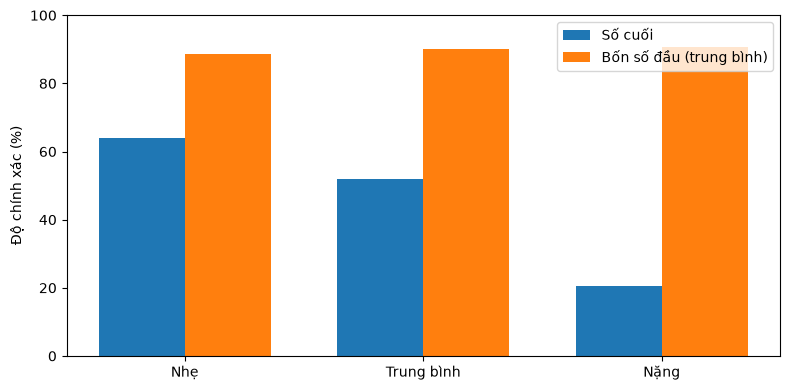

| Tầng | Số ảnh | Độ sáng TB | Tương phản TB | Laplacian variance TB |
| --- | --- | --- | --- | --- |
| light | 437 | 168.97 | 38.95 | 605.83 |
| medium | 1156 | 171.33 | 38.31 | 635.89 |
| heavy | 407 | 173.00 | 39.98 | 653.46 |

In [2]:
rows=[]
for tier in TIERS:
    x=get(summary,'baseline',tier)
    rows.append(dict(tier=TIER_NAMES[TIERS.index(tier)],n=x['n'],d5=percent(x['d5']),first4=percent(x['first4']),full=percent(x['full'])))
show_table(rows,[('tier','Tầng'),('n','Số ảnh'),('d5','Đúng số cuối'),('first4','Trung bình bốn số đầu'),('full','Đúng cả chỉ số')])
fig,ax=plt.subplots(figsize=(8,4))
x=np.arange(3)
for offset,key,label in [(-0.18,'d5','Số cuối'),(0.18,'first4','Bốn số đầu (trung bình)')]:
    ax.bar(x+offset,[100*float(get(summary,'baseline',t)[key]) for t in TIERS],width=0.36,label=label)
ax.set_xticks(x,TIER_NAMES); ax.set_ylim(0,100); ax.set_ylabel('Độ chính xác (%)'); ax.legend(); fig.tight_layout(); plt.show()
controls=read_table(PHUC,'e1_control_summary.csv')
show_table([{**r, **{k:f'{float(r[k]):.2f}' for k in ('brightness_mean','contrast_mean','sharpness_mean')}} for r in controls],
           [('tier','Tầng'),('n','Số ảnh'),('brightness_mean','Độ sáng TB'),('contrast_mean','Tương phản TB'),('sharpness_mean','Laplacian variance TB')])


### Nhận xét E1

Baseline số cuối giảm 64,07% → 20,64% từ tầng nhẹ sang nặng, trong khi trung bình bốn số đầu tăng nhẹ 88,62% → 90,79%. Proxy độ sáng và độ nét không cho thấy tầng nặng tối hơn hoặc mờ hơn. Kết quả phù hợp với khó khăn tập trung ở ô cuối, nhưng chưa đủ chứng minh nhân quả: không có ID loại đồng hồ và chưa kiểm định tương đương các yếu tố nhiễu. Thước đo có thể nhầm khoảng trống trong chữ số thành khe nền.

## E2 - Khảo sát tham số trên dev_val

Pitch 54/58/62, bán kính dịch ngang 2/6/10, ngưỡng chuyển nhãn 0,4/0,5/0,6 tạo 27 cấu hình. Chọn accuracy chữ số cuối cao nhất toàn dev_val; hòa chọn cấu hình đầu tiên. Không chọn cấu hình riêng theo tầng hoặc theo eval.

| Pitch | Dịch ngang | Ngưỡng | Số cuối | Nhẹ | Trung bình | Nặng |
| --- | --- | --- | --- | --- | --- | --- |
| 54 | 2 | 0.4 | 39.43% | 46.90% | 49.32% | 21.83% |
| 54 | 2 | 0.5 | 39.30% | 47.39% | 49.23% | 21.32% |
| 54 | 2 | 0.6 | 38.91% | 46.15% | 49.04% | 21.07% |
| 54 | 6 | 0.4 | 44.98% | 57.57% | 54.32% | 25.51% |
| 54 | 6 | 0.5 | 44.85% | 57.57% | 54.32% | 25.13% |
| 54 | 6 | 0.6 | 44.32% | 56.33% | 54.14% | 24.49% |
| 54 | 10 | 0.4 | 42.79% | 57.32% | 52.05% | 22.46% |
| 54 | 10 | 0.5 | 42.62% | 57.57% | 51.87% | 22.08% |
| 54 | 10 | 0.6 | 42.18% | 56.33% | 51.68% | 21.70% |
| 58 | 2 | 0.4 | 37.64% | 45.16% | 46.41% | 21.57% |
| 58 | 2 | 0.5 | 37.60% | 45.41% | 46.41% | 21.32% |
| 58 | 2 | 0.6 | 37.42% | 44.91% | 46.22% | 21.32% |
| 58 | 6 | 0.4 | 45.41% | 59.55% | 54.23% | 25.89% |
| 58 | 6 | 0.5 | 45.20% | 59.80% | 54.05% | 25.38% |
| 58 | 6 | 0.6 | 44.98% | 59.31% | 53.96% | 25.13% |
| 58 | 10 | 0.4 | 43.45% | 57.32% | 52.14% | 24.24% |
| 58 | 10 | 0.5 | 43.41% | 57.57% | 51.96% | 24.24% |
| 58 | 10 | 0.6 | 43.23% | 56.82% | 51.87% | 24.24% |
| 62 | 2 | 0.4 | 37.51% | 46.15% | 45.31% | 22.21% |
| 62 | 2 | 0.5 | 37.47% | 46.15% | 45.22% | 22.21% |
| 62 | 2 | 0.6 | 37.51% | 46.15% | 45.31% | 22.21% |
| 62 | 6 | 0.4 | 45.11% | 58.06% | 53.14% | 27.28% |
| 62 | 6 | 0.5 | 45.07% | 58.31% | 53.05% | 27.16% |
| 62 | 6 | 0.6 | 44.80% | 57.82% | 52.87% | 26.90% |
| 62 | 10 | 0.4 | 42.79% | 57.57% | 49.68% | 25.63% |
| 62 | 10 | 0.5 | 42.84% | 58.06% | 49.50% | 25.76% |
| 62 | 10 | 0.6 | 42.62% | 57.82% | 49.32% | 25.51% |

Cấu hình đã chốt: pitch=58, dịch ngang=6, ngưỡng=0.4; accuracy dev_val=45.41%.

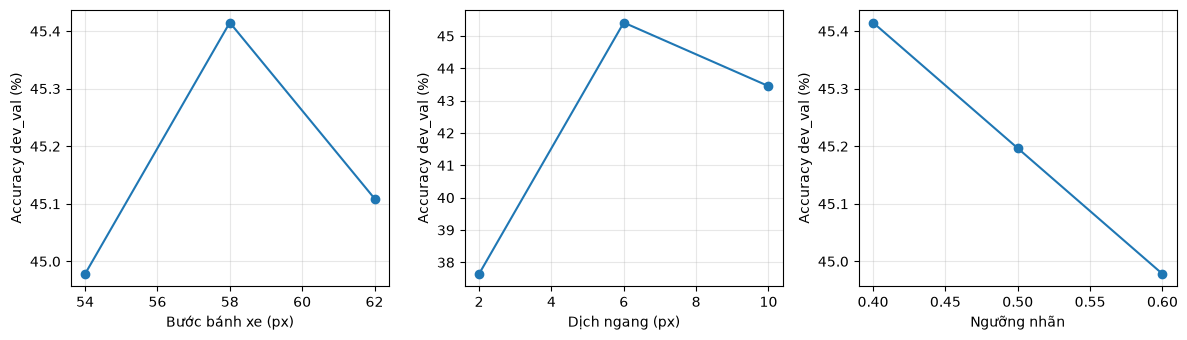

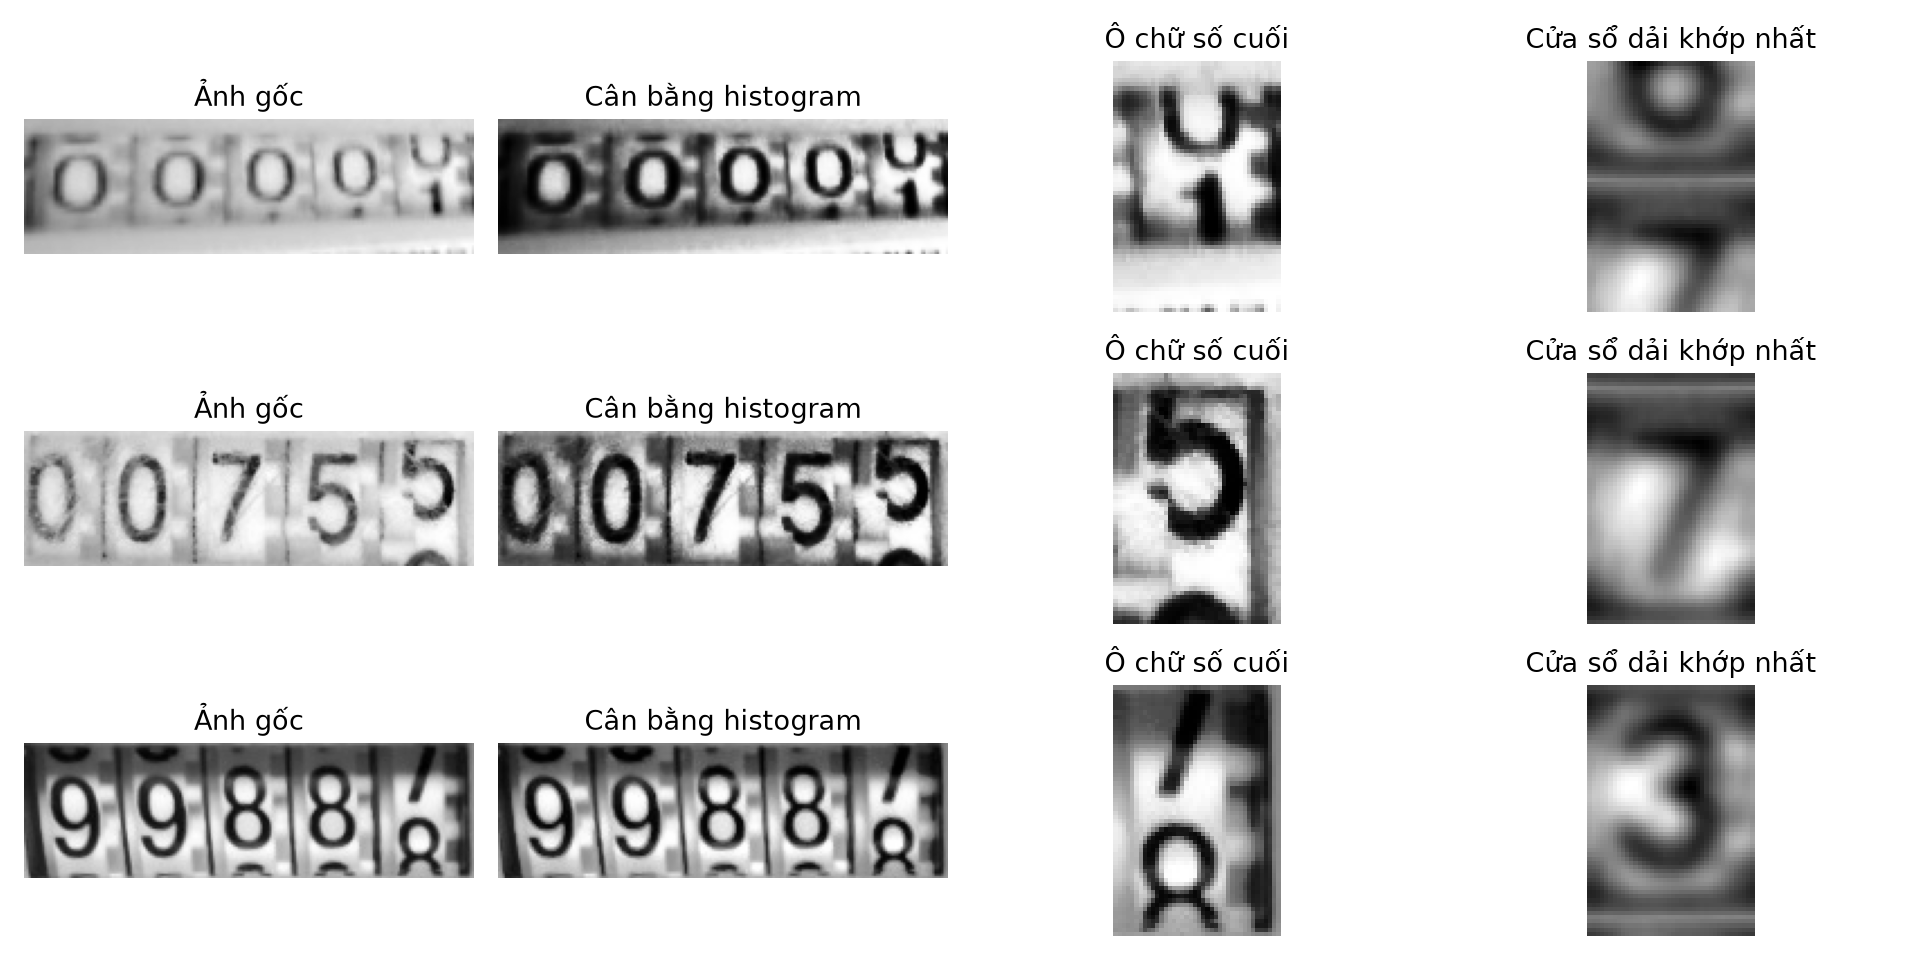

In [3]:
show_table([{**r,'accuracy':percent(r['last_accuracy']),'light':percent(r['light']),'medium':percent(r['medium']),'heavy':percent(r['heavy'])} for r in grid],
           [('pitch','Pitch'),('max_shift','Dịch ngang'),('threshold','Ngưỡng'),('accuracy','Số cuối'),('light','Nhẹ'),('medium','Trung bình'),('heavy','Nặng')])
best=max(grid,key=lambda r:float(r['last_accuracy']))
for key in ('pitch','max_shift','threshold'):
    assert float(best[key])==float(selected['config'][key])
display(Markdown(f"Cấu hình đã chốt: pitch={best['pitch']}, dịch ngang={best['max_shift']}, ngưỡng={best['threshold']}; accuracy dev_val={percent(best['last_accuracy'])}."))
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,key,label in zip(axes,('pitch','max_shift','threshold'),('Bước bánh xe (px)','Dịch ngang (px)','Ngưỡng nhãn')):
    group=[r for r in grid if all(float(r[k])==float(best[k]) for k in ('pitch','max_shift','threshold') if k!=key)]
    group.sort(key=lambda r:float(r[key]))
    ax.plot([float(r[key]) for r in group],[100*float(r['last_accuracy']) for r in group],marker='o')
    ax.set_xlabel(label); ax.set_ylabel('Accuracy dev_val (%)'); ax.grid(alpha=.3)
fig.tight_layout(); plt.show()
image=PHUC/'e2_intermediates.png'
assert image.is_file()
display(Image(filename=str(image)))


### Nhận xét E2

Giữ pitch=58 và ngưỡng=0,4: dịch ngang 2/6/10 cho 37,64% / 45,41% / 43,45%. Bán kính 6 cân bằng việc bù lệch và nguy cơ khớp nhầm. Giữ dịch ngang=6, ngưỡng=0,4: pitch 54/58/62 cho 44,98% / 45,41% / 45,11%, chênh nhỏ. Giữ pitch=58, dịch ngang=6: ngưỡng 0,4/0,5/0,6 cho 45,41% / 45,20% / 44,98%. Ngưỡng tốt nhất nằm ở biên miền dò; không khẳng định tối ưu ngoài miền đã khảo sát.

Hình đặt ảnh đầu vào, cân bằng histogram, ô cuối và mẫu dải khớp cạnh nhau. Ba ảnh lấy ở chỉ số cố định trong dev_val. Mẫu trung bình bị nhòe và khác kiểu chữ có thể gây sai; đó là giả thuyết giải thích, chưa phải nguyên nhân đã chứng minh.

### E2 ảnh theo tham số và ảnh trung gian

Hai hình bổ sung từ report/make_figures.py đặt kết quả ảnh và chỉ số cạnh nhau cho ba giá trị của mỗi tham số. Ảnh dev_val được chọn theo quy tắc cố định: half-word tầng nặng, dịch ngang 2 đọc sai, dịch ngang 6 đọc đúng và pha gần proxy độ lăn. Đây là ảnh minh họa có chủ đích để giải thích khác biệt, không đại diện cho accuracy toàn tập. Các tỷ lệ toàn dev_val vẫn lấy từ 27 cấu hình E2.

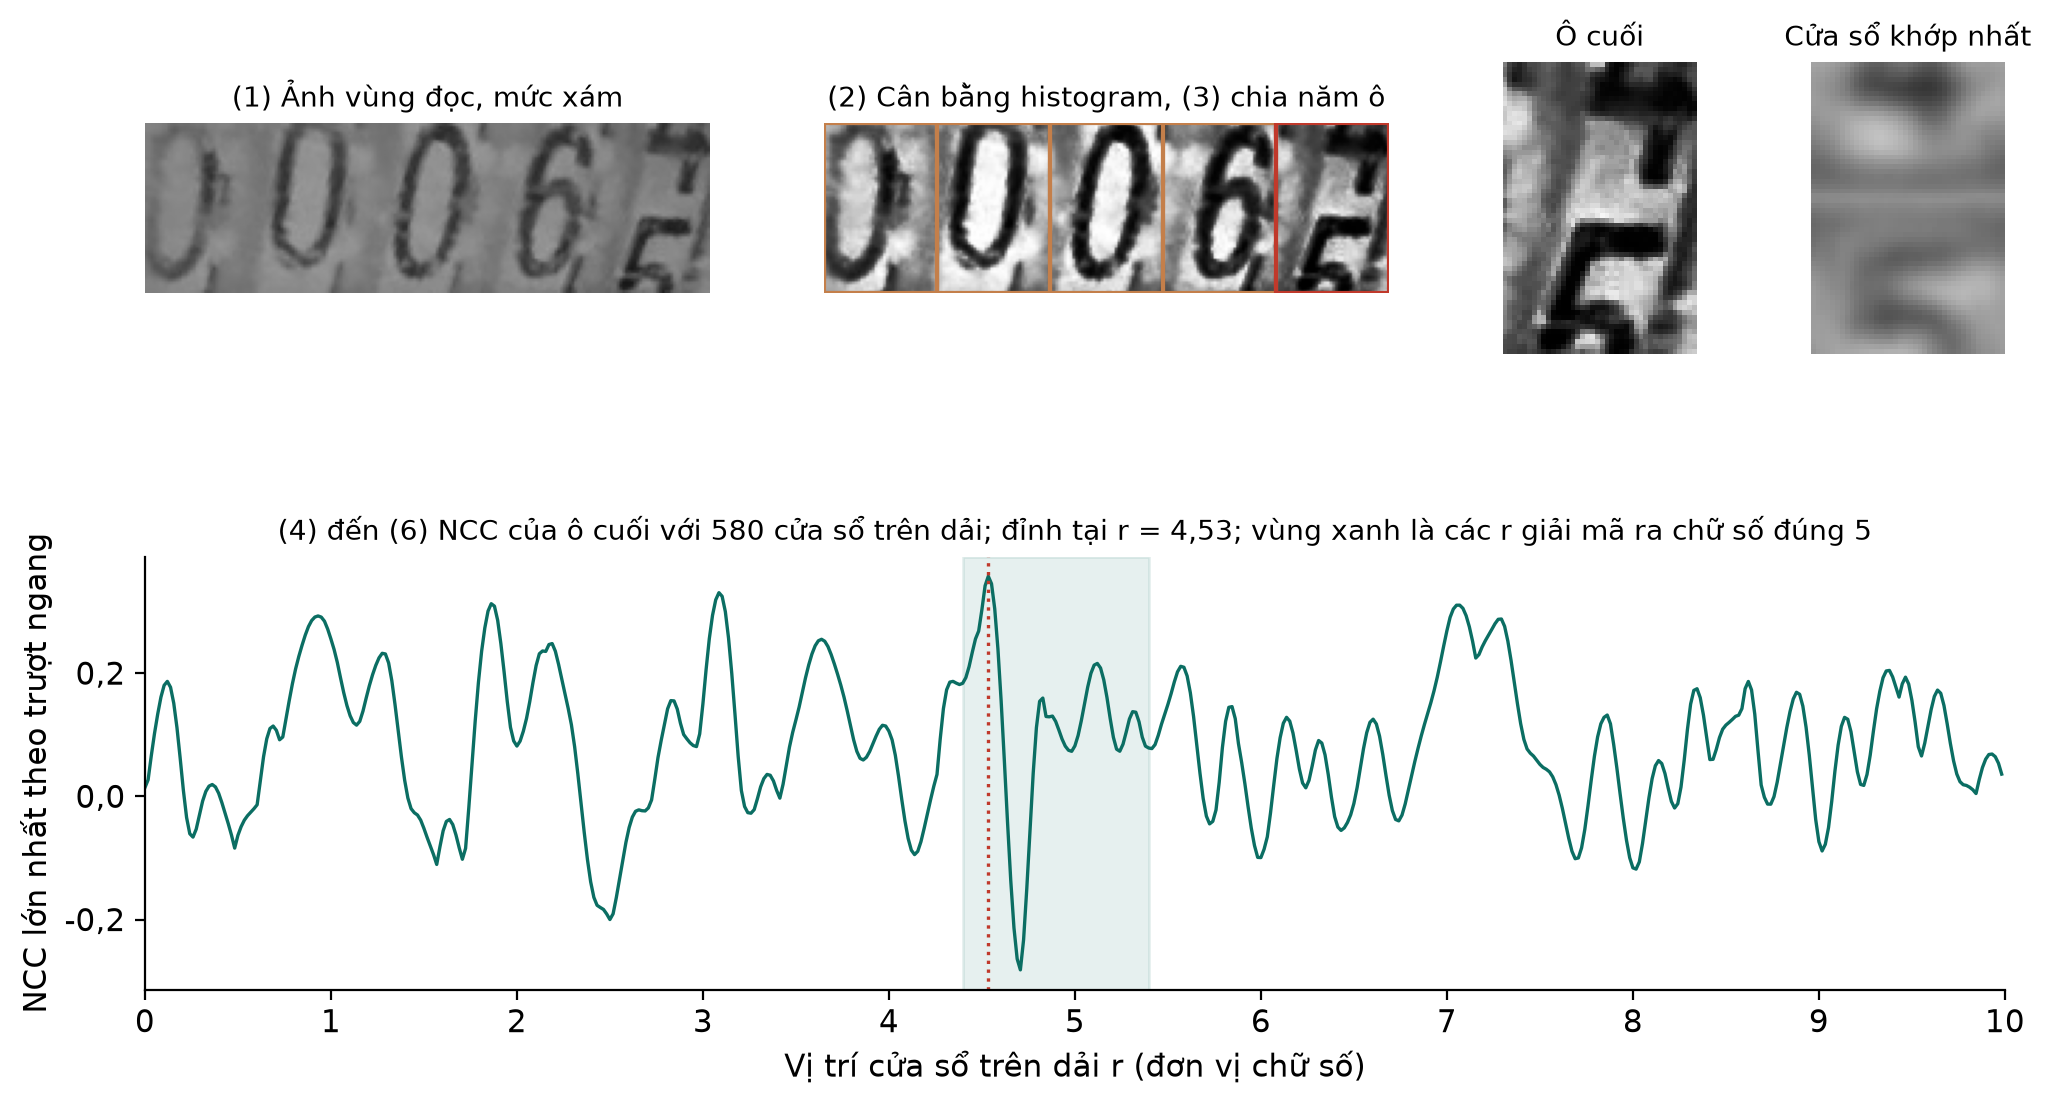

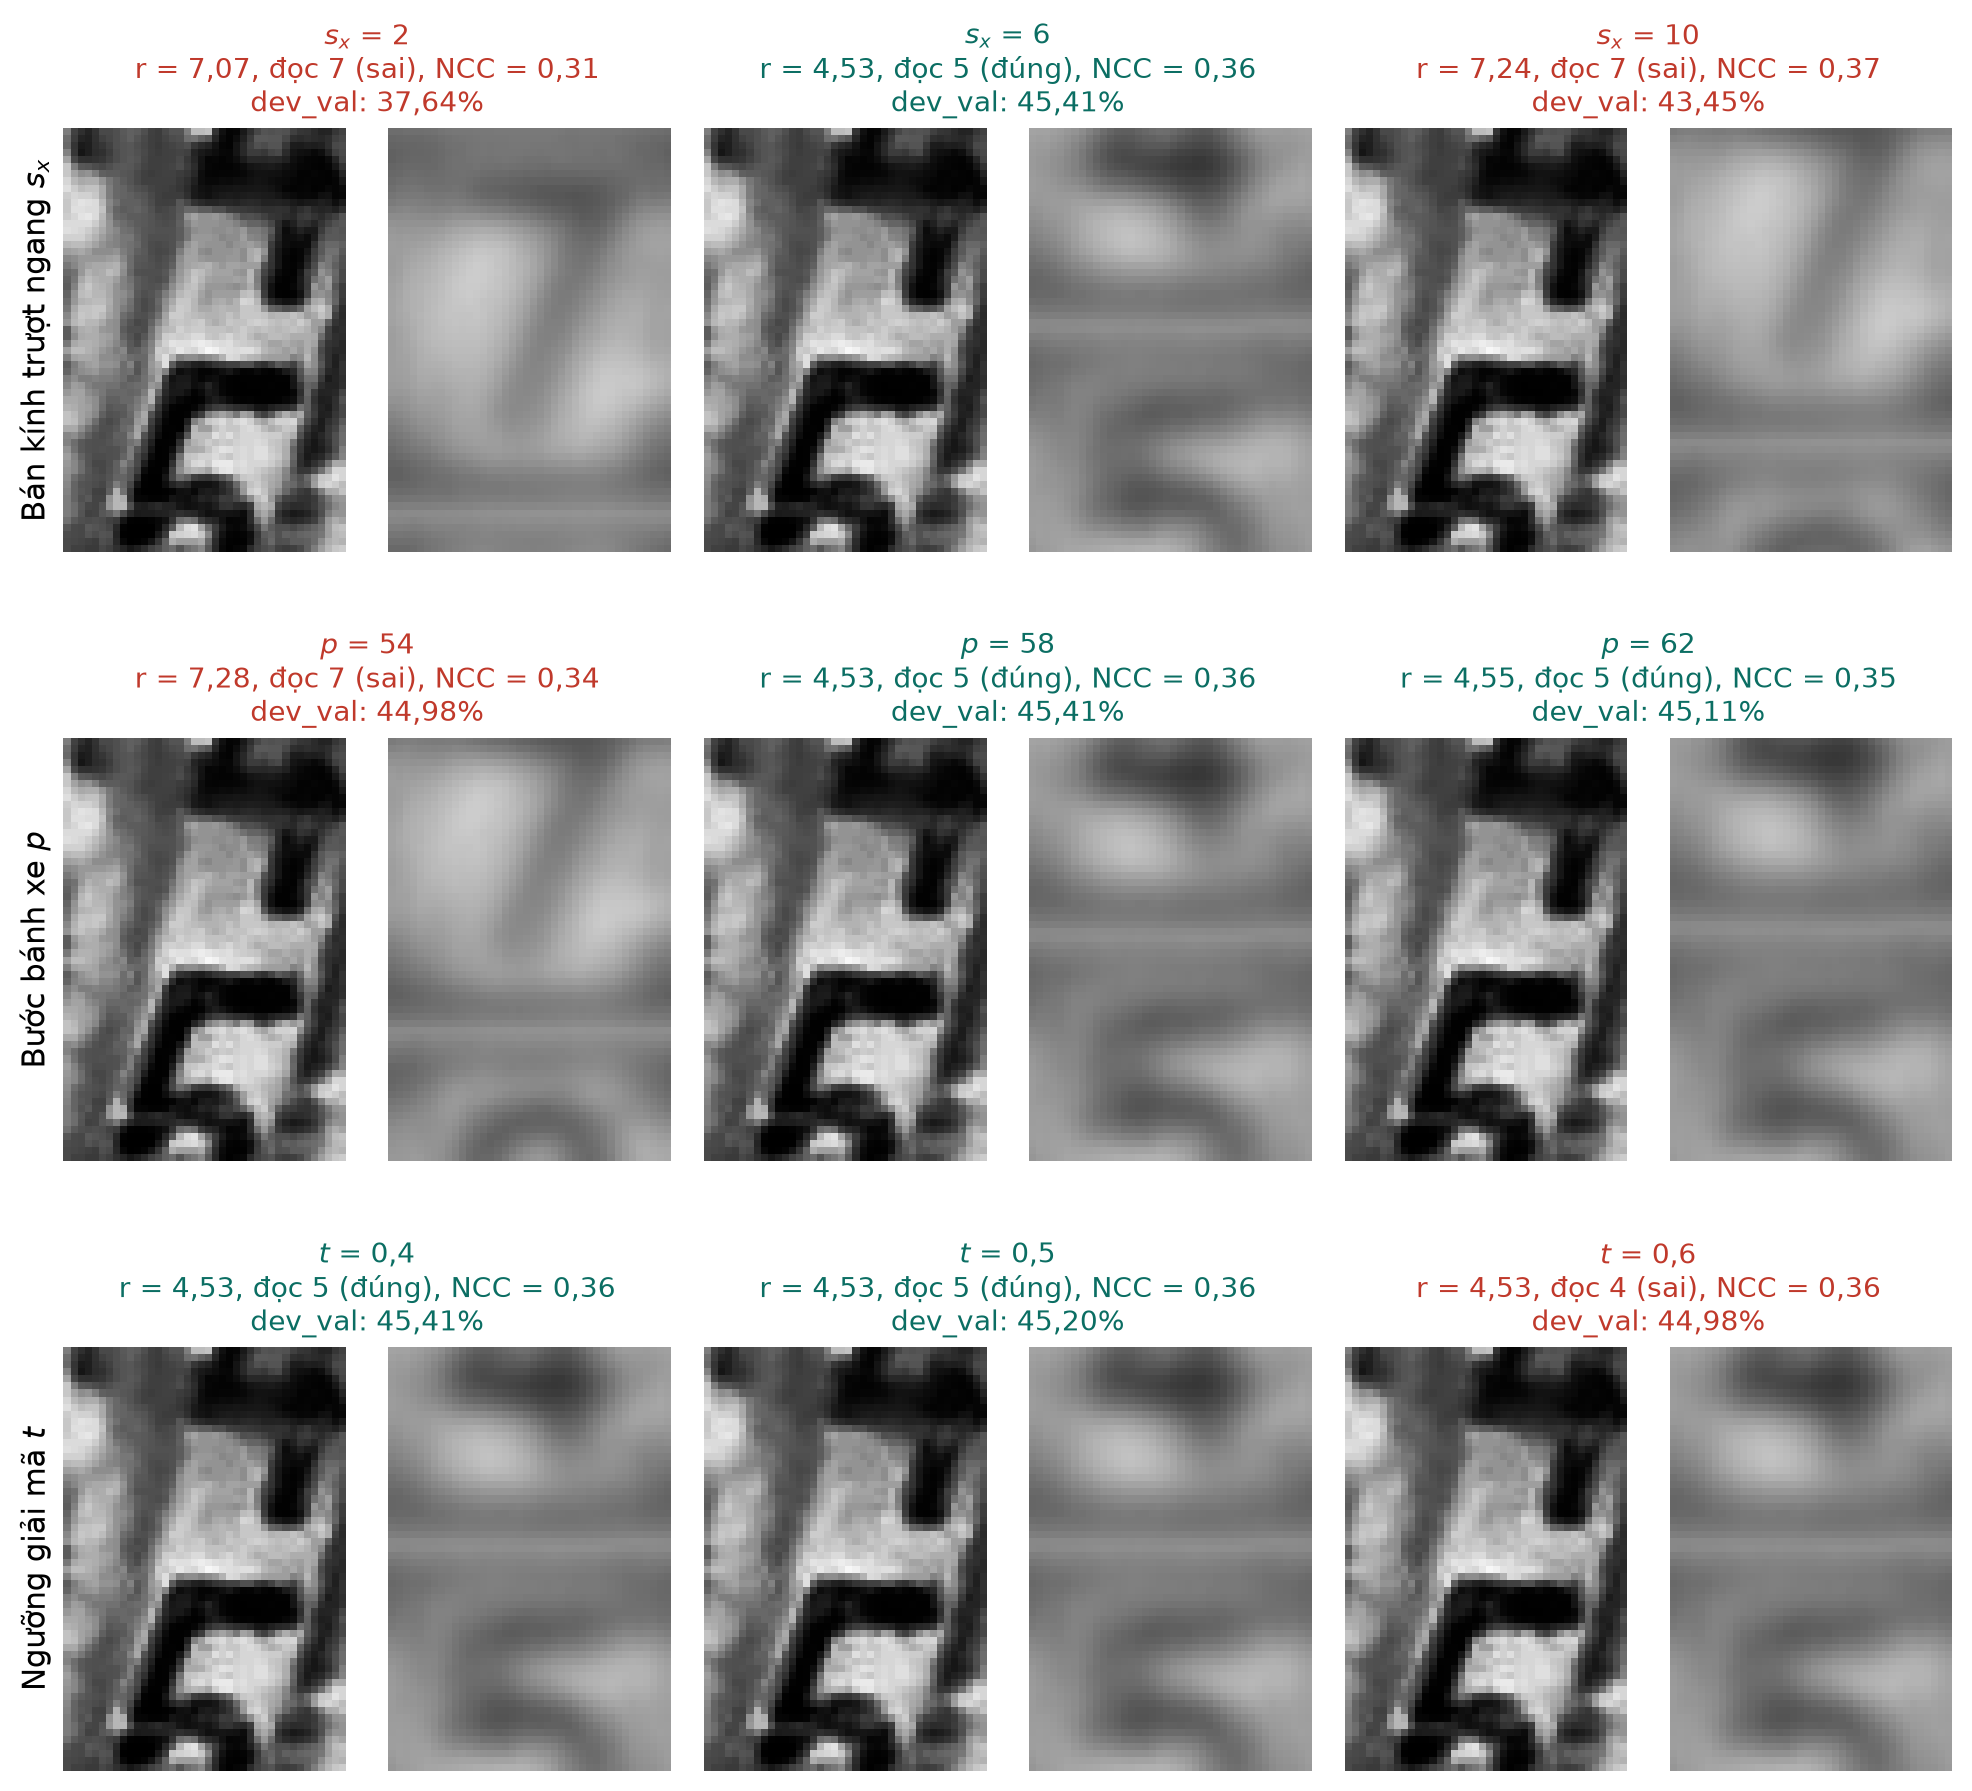

In [4]:
for name in ('fig-pipeline.png', 'fig-e2-params.png'):
    path = ROOT/'report/figures'/name
    assert path.is_file(), f'Thiếu hình bổ sung {name}'
    display(Image(filename=str(path)))

## E3 - Loại bỏ thành phần xử lý độ lăn

Nguồn: `experiments/quang/results/e3_summary.csv`. Ba phiên bản giữ nguyên dữ liệu, mẫu, tiền xử lý và cấu hình đã chốt:

- Baseline: `enabled=False`, trở về baseline cùng max_shift.
- Bỏ pha trung gian: `continuous=False`, chỉ giữ pha gần tâm chữ số trong bán kính max_shift.
- Đề xuất đầy đủ: cho phép tìm cả pha nằm giữa hai chữ số.

Hai phép tắt có ý nghĩa khác nhau. E3 dùng bản bỏ pha trung gian để cô lập vai trò của pha liên tục.

| Phiên bản | Toàn tập | Nhẹ | Trung bình | Nặng |
| --- | --- | --- | --- | --- |
| Baseline | 48.25% | 64.07% | 51.99% | 20.64% |
| Bỏ pha trung gian | 48.95% | 65.90% | 52.25% | 21.38% |
| Đề xuất | 54.45% | 64.76% | 59.60% | 28.75% |

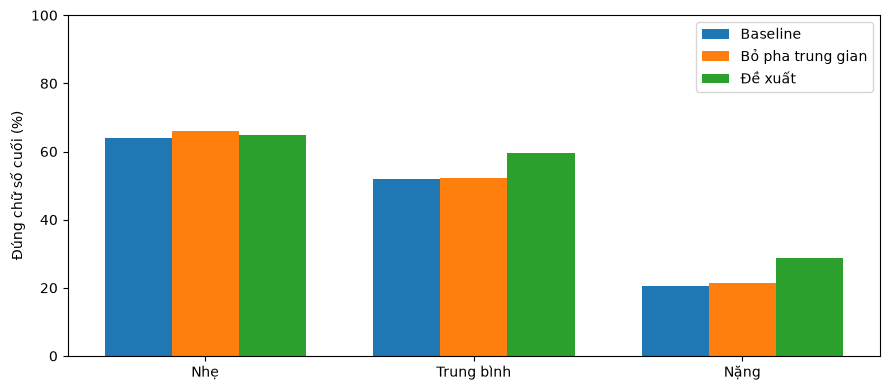

Bốn vị trí đầu có cùng accuracy ở cả ba phiên bản.


In [5]:
METHODS=['baseline','discrete_phase','proposed']
LABELS=['Baseline','Bỏ pha trung gian','Đề xuất']
show_table([dict(method=LABELS[METHODS.index(method)],**{t:percent(get(e3,method,t)['d5']) for t in ('all',*TIERS)}) for method in METHODS],
           [('method','Phiên bản'),('all','Toàn tập'),('light','Nhẹ'),('medium','Trung bình'),('heavy','Nặng')])
fig,ax=plt.subplots(figsize=(9,4))
x=np.arange(3)
for i,method in enumerate(METHODS):
    ax.bar(x+(i-1)*.25,[100*float(get(e3,method,t)['d5']) for t in TIERS],width=.25,label=LABELS[i])
ax.set_xticks(x,TIER_NAMES); ax.set_ylabel('Đúng chữ số cuối (%)'); ax.set_ylim(0,100); ax.legend(); fig.tight_layout(); plt.show()
for tier in ('all',*TIERS):
    for key in ('d1','d2','d3','d4'):
        assert len({get(e3,m,tier)[key] for m in METHODS})==1
print('Bốn vị trí đầu có cùng accuracy ở cả ba phiên bản.')


### Nhận xét E3

Toàn tập: bỏ pha trung gian đạt 48,95%, gần baseline 48,25%, thấp hơn đề xuất 54,45%. Ở tầng nặng: 21,38% so với 28,75%, chênh 7,37 điểm phần trăm. Kết quả hỗ trợ vai trò của pha trung gian trong phần tăng điểm ở tầng trung bình/nặng. Không phải mọi tầng đều tăng: ở tầng nhẹ bản bỏ pha trung gian 65,90% cao hơn đề xuất 64,76%. Bốn số đầu không đổi vì chỉ thay bước đọc ô cuối.

## Độ tin cậy thống kê trên ảnh thật

Ghép baseline và đề xuất theo tên ảnh từ `e3_predictions.csv`. Với mỗi ảnh đặt X bằng 1 nếu chỉ đề xuất đúng, -1 nếu chỉ baseline đúng, và 0 nếu cả hai cùng đúng hoặc cùng sai. Hiệu accuracy là trung bình X. KTC Wald 95% dùng hiệu cộng/trừ 1,96 lần sai số chuẩn, với phương sai cắm ước lượng từ X. McNemar chính xác dùng `scipy.stats.binomtest` trên hai nhóm bất đồng.

Toàn tập là phép so chính. Các phép so theo tầng mang tính phân tích bổ sung, chưa hiệu chỉnh nhiều kiểm định. Các phép tính giả định ảnh là các đơn vị quan sát độc lập. Không có ID đồng hồ để điều chỉnh phụ thuộc giữa ảnh cùng đồng hồ.

In [6]:
from scipy.stats import binomtest
paired_rows = read_table(QUANG, 'e3_predictions.csv')
by_method = {}
for method in ('baseline', 'proposed'):
    chosen = [r for r in paired_rows if r['method'] == method]
    mapping = {r['name']: r for r in chosen}
    assert len(chosen) == len(mapping), f'Trùng tên ảnh trong {method}'
    by_method[method] = mapping
assert set(by_method['baseline']) == set(by_method['proposed'])
assert len(by_method['baseline']) == 2000
paired_stats = []
for tier in ('all', *TIERS):
    names = [name for name, row in by_method['baseline'].items()
             if tier == 'all' or row['tier'] == tier]
    base_correct, prop_correct = [], []
    for name in names:
        b, p = by_method['baseline'][name], by_method['proposed'][name]
        assert b['reading'] == p['reading'] and b['tier'] == p['tier']
        base_correct.append(b['reading'][-1] == b['prediction'][-1])
        prop_correct.append(p['reading'][-1] == p['prediction'][-1])
    b = np.asarray(base_correct, dtype=bool)
    p = np.asarray(prop_correct, dtype=bool)
    wins = int(np.sum(p & ~b))
    losses = int(np.sum(b & ~p))
    x = p.astype(float) - b.astype(float)
    difference = float(x.mean())
    se = float(np.sqrt(np.mean(x*x) - difference*difference) / np.sqrt(len(x)))
    low, high = difference - 1.96*se, difference + 1.96*se
    pvalue = float(binomtest(wins, wins+losses, 0.5).pvalue) if wins+losses else 1.0
    assert abs(difference - (float(get(e3, 'proposed', tier)['d5']) - float(get(e3, 'baseline', tier)['d5']))) < 1e-12
    paired_stats.append(dict(tier=tier, n=len(x), wins=wins, losses=losses,
        difference=difference, ci_low=low, ci_high=high, mcnemar_p=pvalue))
show_table([dict(tier=r['tier'], n=r['n'], wins=r['wins'], losses=r['losses'],
    difference=f"{100*r['difference']:+.2f}",
    ci=f"{100*r['ci_low']:+.2f} tới {100*r['ci_high']:+.2f}",
    p=f"{r['mcnemar_p']:.3g}") for r in paired_stats],
    [('tier','Tầng'),('n','Số ảnh'),('wins','Chỉ đề xuất đúng'),('losses','Chỉ baseline đúng'),
     ('difference','Hiệu (điểm phần trăm)'),('ci','KTC 95% (điểm phần trăm)'),('p','McNemar p')])
assert next(r for r in paired_stats if r['tier']=='all')['wins'] == 230
assert next(r for r in paired_stats if r['tier']=='all')['losses'] == 106


| Tầng | Số ảnh | Chỉ đề xuất đúng | Chỉ baseline đúng | Hiệu (điểm phần trăm) | KTC 95% (điểm phần trăm) | McNemar p |
| --- | --- | --- | --- | --- | --- | --- |
| all | 2000 | 230 | 106 | +6.20 | +4.42 tới +7.98 | 1.14e-11 |
| light | 437 | 28 | 25 | +0.69 | -2.58 tới +3.95 | 0.784 |
| medium | 1156 | 152 | 64 | +7.61 | +5.16 tới +10.07 | 1.95e-09 |
| heavy | 407 | 50 | 17 | +8.11 | +4.25 tới +11.97 | 6.74e-05 |

### Nhận xét thống kê

Toàn eval, đề xuất tăng 6,20 điểm phần trăm, KTC 95% 4,42 tới 7,98, McNemar p khoảng 1,1 × 10⁻¹¹. Tầng nặng tăng 8,11 điểm, KTC 4,25 tới 11,97, p khoảng 6,7 × 10⁻⁵. Tầng nhẹ tăng 0,69 điểm, KTC -2,58 tới 3,95 và p khoảng 0,78. Chưa có bằng chứng tăng accuracy ở tầng nhẹ với mức ý nghĩa 0,05, đồng thời phép thử này cũng không chứng minh hai phương pháp tương đương hoặc không gây hại.

Dù mức tăng toàn tập và tầng nặng có bằng chứng thống kê, accuracy số cuối ở tầng nặng vẫn chỉ 28,75%. Kết luận về ứng dụng thực tế cần xét cả mức accuracy tuyệt đối và các giả định đầu vào.

## E4 - Điểm gãy và đối chiếu dự đoán

Nguồn: các bảng `e4_*` và `e3_e4_report.json` của Quang. Ghép 165 cặp ô ít lăn từ dev_val, quét φ=0 đến 0,5 bước 0,05. Hai ô có thể đến từ các đồng hồ khác nhau; chu kỳ ghép dùng chiều cao ô 60 hàng.

Tiêu chí trong đường cong là tỉ lệ đọc ra d hoặc d+1, không phải accuracy nhãn chính xác trên eval. Không so trực tiếp các phần trăm này với E1/E3. “Điểm gãy” theo quy ước E4 là mức φ đầu tiên có tỉ lệ này dưới 50%.

| φ | Số cặp | Độ lăn đo được | Baseline ±2 | Baseline ±6 | Baseline ±10 | Đề xuất |
| --- | --- | --- | --- | --- | --- | --- |
| 0.0 | 165 | 0.179 | 52.73% | 66.06% | 70.91% | 66.67% |
| 0.05 | 165 | 0.301 | 53.94% | 66.67% | 68.48% | 70.30% |
| 0.1 | 165 | 0.338 | 46.67% | 63.64% | 67.27% | 67.27% |
| 0.15 | 165 | 0.346 | 41.82% | 55.76% | 70.30% | 65.45% |
| 0.2 | 165 | 0.404 | 30.91% | 47.27% | 61.82% | 67.27% |
| 0.25 | 165 | 0.496 | 32.73% | 36.36% | 50.30% | 66.06% |
| 0.3 | 165 | 0.593 | 28.48% | 32.12% | 36.36% | 64.85% |
| 0.35 | 165 | 0.688 | 21.82% | 31.52% | 32.73% | 61.82% |
| 0.4 | 165 | 0.769 | 24.24% | 22.42% | 27.88% | 58.79% |
| 0.45 | 165 | 0.839 | 27.27% | 21.21% | 22.42% | 58.79% |
| 0.5 | 165 | 0.848 | 25.45% | 20.00% | 19.39% | 56.36% |

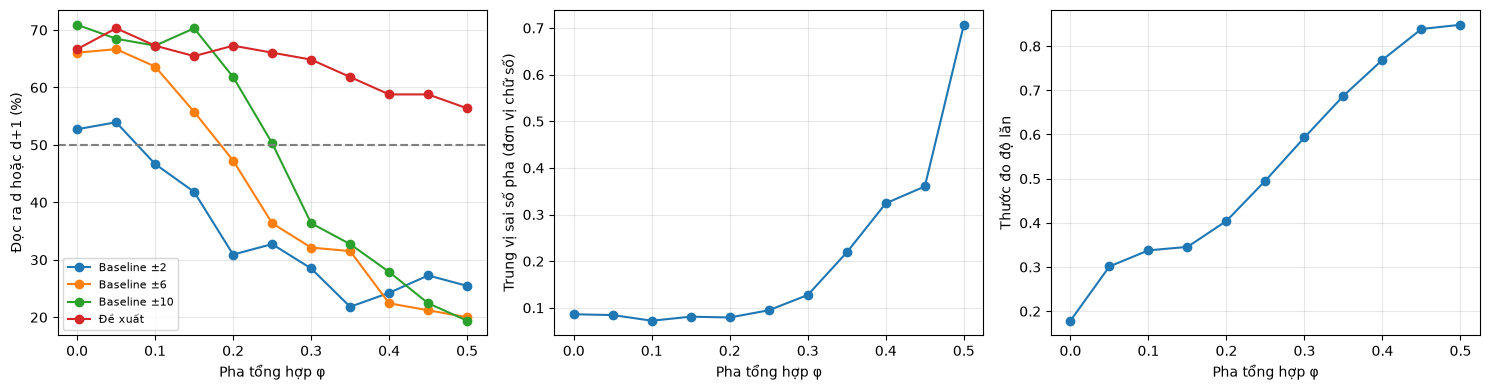

baseline_s2 : điểm gãy φ=0.10
baseline_s6 : điểm gãy φ=0.20
baseline_s10 : điểm gãy φ=0.30
proposed : chưa xuống dưới 50% trong miền khảo sát


| Tầng | Nhóm chiều cao | Phương pháp | Số ảnh | Đúng số cuối |
| --- | --- | --- | --- | --- |
| light | near | baseline | 407 | 64.62% |
| light | near | proposed | 407 | 66.34% |
| light | far | baseline | 30 | 56.67% |
| light | far | proposed | 30 | 43.33% |
| medium | near | baseline | 1113 | 52.29% |
| medium | near | proposed | 1113 | 60.02% |
| medium | far | baseline | 43 | 44.19% |
| medium | far | proposed | 43 | 48.84% |
| heavy | near | baseline | 389 | 20.05% |
| heavy | near | proposed | 389 | 28.28% |
| heavy | far | baseline | 18 | 33.33% |
| heavy | far | proposed | 18 | 38.89% |

In [7]:
show_table([{**r,'roll':f"{float(r['measured_roll']):.3f}", **{key:percent(r[key]) for key in ('baseline_s2_reads_lower_or_next','baseline_s6_reads_lower_or_next','baseline_s10_reads_lower_or_next','proposed_reads_lower_or_next')}} for r in curve],
           [('phi','φ'),('n','Số cặp'),('roll','Độ lăn đo được'),('baseline_s2_reads_lower_or_next','Baseline ±2'),('baseline_s6_reads_lower_or_next','Baseline ±6'),('baseline_s10_reads_lower_or_next','Baseline ±10'),('proposed_reads_lower_or_next','Đề xuất')])
phi=[float(r['phi']) for r in curve]
fig,axes=plt.subplots(1,3,figsize=(15,4))
for key,label in [('baseline_s2_reads_lower_or_next','Baseline ±2'),('baseline_s6_reads_lower_or_next','Baseline ±6'),('baseline_s10_reads_lower_or_next','Baseline ±10'),('proposed_reads_lower_or_next','Đề xuất')]:
    axes[0].plot(phi,[100*float(r[key]) for r in curve],marker='o',label=label)
axes[0].axhline(50,color='gray',linestyle='--'); axes[0].set_ylabel('Đọc ra d hoặc d+1 (%)'); axes[0].legend(fontsize=8)
axes[1].plot(phi,[float(r['proposed_phase_median']) for r in curve],marker='o'); axes[1].set_ylabel('Trung vị sai số pha (đơn vị chữ số)')
axes[2].plot(phi,[float(r['measured_roll']) for r in curve],marker='o'); axes[2].set_ylabel('Thước đo độ lăn')
for ax in axes: ax.set_xlabel('Pha tổng hợp φ'); ax.grid(alpha=.3)
fig.tight_layout(); plt.show()
for method,key in [('baseline_s2','baseline_s2_reads_lower_or_next'),('baseline_s6','baseline_s6_reads_lower_or_next'),('baseline_s10','baseline_s10_reads_lower_or_next'),('proposed','proposed_reads_lower_or_next')]:
    first=next((float(r['phi']) for r in curve if float(r[key])<.5),None)
    assert first==report['synthetic']['first_phi_below_break_level'][method]
    print(method, ': chưa xuống dưới 50% trong miền khảo sát' if first is None else f': điểm gãy φ={first:.2f}')
show_table([{**r,'accuracy':percent(r['last_accuracy'])} for r in heights], [('tier','Tầng'),('height_group','Nhóm chiều cao'),('method','Phương pháp'),('n','Số ảnh'),('accuracy','Đúng số cuối')])


### Nhận xét E4 và dự đoán trước thực nghiệm

1. Điểm gãy baseline dời từ 0,10 sang 0,20 và 0,30 khi bán kính tăng 2 → 6 → 10. Hướng dời phù hợp dự đoán, nhưng muộn hơn s/p (0,03; 0,10; 0,17). Quan hệ thay thế (s+w)/p được gợi ý sau khi xem số liệu, chưa kiểm chứng độc lập.
2. Đề xuất chưa xuống dưới 50% theo tiêu chí d hoặc d+1 trong miền tổng hợp đã khảo sát, không có nghĩa là không gãy ở mọi mức pha. Sai số pha trung vị tăng từ 0,128 ở φ=0,30 lên 0,219 ở 0,35 và 0,707 ở 0,50. Trên ảnh thật, accuracy đề xuất vẫn giảm mạnh ở tầng nặng; không khẳng định dự đoán 2 đúng nói chung.
3. Dự đoán phần lớn lỗi chỉ lệch một chữ số không được ủng hộ: trên tầng nặng, 73/290 lỗi của P là lệch một số (25,17%). Nhầm mẫu chữ số là hạn chế lớn, không chỉ việc chọn ngưỡng chuyển nhãn.
4. Riêng kiểm tra cũ trên ảnh thật chưa kết luận về ngưỡng lệch chiều cao 9%: tầng nặng nhóm xa chỉ có 18 ảnh (38,89%), còn nhóm gần 389 ảnh (28,28%). Hướng quan sát ngược dự đoán, số mẫu nhỏ và chưa kiểm soát nhiễu.

Độ lăn trung bình tăng từ 0,179 lên 0,848 theo pha tổng hợp, hỗ trợ tính nhạy của thước đo trên cách tổng hợp này. Không thay thế việc thẩm định thước đo trên ảnh thật.

In [8]:
direction=report['direction']
display(Markdown(f"Kiểm tra chiều quay trên {direction['n']} ảnh half-word dev_val: NCC trung bình dải xuôi {direction['forward_mean_score']:.4f}, dải ngược {direction['backward_mean_score']:.4f}. Hai chiều gần nhau, chưa xác định được chiều quay từ phép kiểm tra này."))
show_table([dict(source=p,sha256=h) for p,h in SOURCES.items()],[('source','Nguồn bảng'),('sha256','SHA-256')])
print('Hoàn tất E1 tới E4; các kiểm tra nhất quán đã đạt. Không có bước chọn lại tham số hoặc đánh giá ảnh trong notebook.')


Kiểm tra chiều quay trên 836 ảnh half-word dev_val: NCC trung bình dải xuôi 0.4203, dải ngược 0.4212. Hai chiều gần nhau, chưa xác định được chiều quay từ phép kiểm tra này.

| Nguồn bảng | SHA-256 |
| --- | --- |
| experiments/phuc/results/summary.csv | 6331597fb5f0a702247e51c5589f6fa1b67ba17a627dee54f550dff8feab28a8 |
| experiments/phuc/results/e2_grid.csv | 12c486918ebb16f5659319c912c6e6645c2cbc76111645af701063b44322a19e |
| experiments/quang/results/e3_summary.csv | a10ae6fae49167fe8afdc1674b7d9f0a799486ae3a22cf8e56498cb05e228074 |
| experiments/quang/results/e4_curve.csv | 99fd3fc23669138f14ec30d32783733535d1284d41d5d3d425cbfdc015de8476 |
| experiments/quang/results/e4_height_split.csv | 089a316a8c11b6dea56e29653cbfad5cb1ca8be16a5b6a27c0c20a984f0afdbd |
| experiments/phuc/results/e1_control_summary.csv | bd4015388864c8e5706e4132e40e3690cdc091bff4f791a4329db63665d10ec4 |
| experiments/quang/results/e3_predictions.csv | 3ce897f1fd7c4283f15c174fd71c2ee7633a8a8257043e7a902ad355436b8f62 |

Hoàn tất E1 tới E4; các kiểm tra nhất quán đã đạt. Không có bước chọn lại tham số hoặc đánh giá ảnh trong notebook.


## E4 bổ sung quét lệch bước bánh xe

Giữ mẫu và cấu hình đã chốt, ghép 165 bộ ba d-1, d, d+1 từ dev_val rồi co giãn bước thật về 58(1+m), m từ -20% tới +20% bước 5%. Quét pha 0 tới 0,5 bước 0,1.

Tiêu chí định trước là đọc ra d hoặc d+1 dưới 50%. Tiêu chí bổ sung là trung vị sai số pha vượt 0,25 chữ số. Việc dùng 0,25 làm ngưỡng gãy được quyết định sau khi xem quét pha ban đầu, nên là tiêu chí thăm dò, không phải dự đoán định trước. Co giãn thay cả bước và cỡ chữ, chưa tách riêng hai tác động.

| Lệch bước | Pha đầu có sai số trung vị >0,25 | Tỉ lệ d hoặc d+1 nhỏ nhất | Tại pha | KTC Wilson 95% (%) |
| --- | --- | --- | --- | --- |
| -20% | 0.0 | 48.48% | 0.2 | 40.98 tới 56.06 |
| -15% | 0.0 | 52.12% | 0.1 | 44.54 tới 59.61 |
| -10% | 0.5 | 55.76% | 0.0 | 48.13 tới 63.12 |
| -5% | 0.5 | 55.76% | 0.5 | 48.13 tới 63.12 |
| +0% | 0.5 | 53.33% | 0.5 | 45.73 tới 60.78 |
| +5% | 0.4 | 50.91% | 0.5 | 43.35 tới 58.43 |
| +10% | 0.3 | 51.52% | 0.4 | 43.94 tới 59.02 |
| +15% | 0.3 | 49.09% | 0.4 | 41.57 tới 56.65 |
| +20% | 0.3 | 43.64% | 0.5 | 36.30 tới 51.26 |

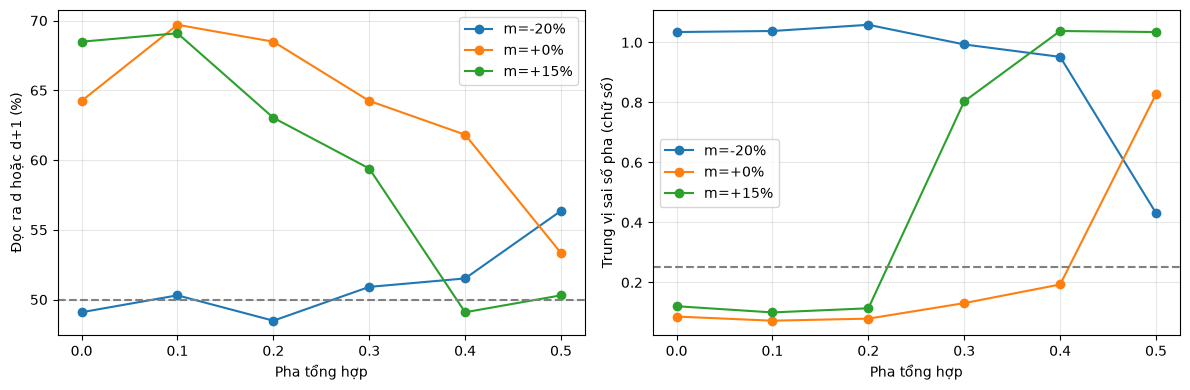

In [9]:
from scipy.stats import binomtest
pitch = read_table(QUANG, 'e4_pitch_curve.csv')
pitch_raw = read_table(QUANG, 'e4_pitch_synthetic.csv')
pitch_report = json.loads((QUANG/'e4_pitch_report.json').read_text())
assert len(pitch) == 54
mismatches = sorted({float(r['mismatch']) for r in pitch})
phase_grid = sorted({float(r['phi']) for r in pitch})
assert len(mismatches)==9 and len(phase_grid)==6
break_rows=[]
for mismatch in mismatches:
    group=sorted([r for r in pitch if float(r['mismatch'])==mismatch], key=lambda r:float(r['phi']))
    for row in group:
        raw=[r for r in pitch_raw if float(r['mismatch'])==mismatch and float(r['phi'])==float(row['phi'])]
        assert len(raw)==int(row['n'])==165
        hits=sum(int(r['proposed']) in (int(r['digit']),(int(r['digit'])+1)%10) for r in raw)
        assert np.isclose(hits/len(raw),float(row['proposed_reads_lower_or_next']))
        assert np.isclose(np.median([abs(float(r['phase_error'])) for r in raw]),float(row['proposed_phase_median']))
    worst=min(group,key=lambda r:float(r['proposed_reads_lower_or_next']))
    observed_phase=next((float(r['phi']) for r in group if float(r['proposed_phase_median'])>.25),None)
    rate=float(worst['proposed_reads_lower_or_next']); count=int(worst['n']); z=1.96
    centre=(rate+z*z/(2*count))/(1+z*z/count)
    half=z*np.sqrt(rate*(1-rate)/count+z*z/(4*count*count))/(1+z*z/count)
    saved=pitch_report['worst_phase_by_mismatch'][str(mismatch)]
    assert np.isclose(rate,saved['min_rate']) and np.isclose(float(worst['phi']),saved['phi_at_min'])
    break_rows.append(dict(m=f'{mismatch*100:+.0f}%', first_phase='Chưa vượt' if observed_phase is None else f'{observed_phase:.1f}',
        minimum=percent(rate), phi=worst['phi'], ci=f'{100*(centre-half):.2f} tới {100*(centre+half):.2f}'))
show_table(break_rows,[('m','Lệch bước'),('first_phase','Pha đầu có sai số trung vị >0,25'),('minimum','Tỉ lệ d hoặc d+1 nhỏ nhất'),('phi','Tại pha'),('ci','KTC Wilson 95% (%)')])
fig,axes=plt.subplots(1,2,figsize=(12,4))
for mismatch in (-.2,0.,.15):
    group=sorted([r for r in pitch if float(r['mismatch'])==mismatch],key=lambda r:float(r['phi']))
    x=[float(r['phi']) for r in group]
    axes[0].plot(x,[100*float(r['proposed_reads_lower_or_next']) for r in group],marker='o',label=f'm={mismatch:+.0%}')
    axes[1].plot(x,[float(r['proposed_phase_median']) for r in group],marker='o',label=f'm={mismatch:+.0%}')
axes[0].axhline(50,color='gray',linestyle='--');axes[0].set_ylabel('Đọc ra d hoặc d+1 (%)')
axes[1].axhline(.25,color='gray',linestyle='--');axes[1].set_ylabel('Trung vị sai số pha (chữ số)')
for ax in axes: ax.set_xlabel('Pha tổng hợp');ax.legend();ax.grid(alpha=.3)
fig.tight_layout();plt.show()

### Diễn giải kết quả bổ sung

Theo sai số định vị pha >0,25, P vượt ngưỡng từ pha 0,4 khi bước khớp, sớm hơn ở pha 0,3 khi bước dài hơn ít nhất 10%; bước ngắn hơn ít nhất 15% gây suy giảm cả ở pha nhỏ. Theo tiêu chí đọc d hoặc d+1 dưới 50%, mức lệch đầu tiên quan sát được là +15% và -20%. Tại +15%, tỷ lệ nhỏ nhất 49,09% có KTC Wilson 95% khoảng 41,6 tới 56,7%, nên chưa có bằng chứng chắc chắn tỷ lệ thực thấp hơn 50%.

KTC tại cực tiểu là khoảng điểm cho một ô lưới, chưa hiệu chỉnh việc chọn cực tiểu trên nhiều ô hoặc việc lặp lại ô nguồn. Dự đoán 4 được báo cáo là đúng một phần theo bằng chứng tổng hợp, còn kiểm tra ảnh thật 18 ảnh vẫn chưa kết luận. Cùng với các kết quả trước, báo cáo xếp ba dự đoán đúng một phần và một dự đoán sai. Không diễn giải phép thử thăm dò như xác nhận độc lập ngưỡng vật lý 9%.

## Kết luận và giới hạn

Trên 2.000 ảnh thật, P tăng accuracy số cuối 48,25% → 54,45% và cả chỉ số 37,15% → 42,10%. E3 hỗ trợ đóng góp của pha trung gian. E4 cho thấy baseline chịu được pha lớn hơn khi tăng vùng dịch, còn P vẫn gặp nhầm kiểu chữ và định vị pha kém ở pha lớn.

Ảnh tổng hợp dùng lại ô từ một kho nhỏ, chỉ 7 ảnh cho số 7; 165 cặp không phải 165 đồng hồ độc lập. Phép so ghép cặp cho thấy mức tăng toàn eval 6,20 điểm phần trăm, KTC 95% từ 4,42 tới 7,98, McNemar p khoảng 1,1 × 10⁻¹¹. Tầng nặng tăng 8,11 điểm, KTC từ 4,25 tới 11,97. Tầng nhẹ tăng 0,69 điểm, p khoảng 0,78 nên chưa có bằng chứng cải thiện ở mức ý nghĩa 0,05. Các phép tính coi ảnh là đơn vị quan sát và chưa hiệu chỉnh cho nhiều phép so sánh theo tầng. KTC phản ánh biến thiên lấy mẫu ảnh, không bao gồm biến thiên do chọn tham số hoặc quan hệ giữa ảnh của cùng đồng hồ khi chưa có ID nhóm. Chiều quay, pitch chung, proxy độ lăn và giả định biết hướng ảnh đều cần công bố khi thuyết trình. Không sửa dự đoán ban đầu sau khi xem kết quả.

Tái lập bảng ảnh thật và E2: `python experiments/run_phuc.py --stage tune`, sau đó `--stage evaluate`. E3/E4: `python experiments/run_e3_e4.py`. Các lệnh này cần bộ ảnh đầy đủ; chạy notebook chỉ cần các kết quả đã commit. Phép quét lệch bước bổ sung được trình bày trong mục E4 bên dưới.